# 1. Setup

In [ ]:
# 1. Setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

drive.mount('/content/drive')

SEED = 42
np.random.seed(SEED)

path = '/content/drive/MyDrive/ML_Classification_Diabetes_Prediction/'
train = pd.read_csv(path + 'train.csv')
test = pd.read_csv(path + 'test.csv')

print('Train shape:', train.shape)
print('Test shape:', test.shape)
print('\nTrain columns:', list(train.columns))
print('Test columns:', list(test.columns))
print('\nDuplicates in train:', train.duplicated().sum())
print('\nData types:')
print(train.dtypes)
train.head()

Mounted at /content/drive
Train shape: (614, 10)
Test shape: (154, 9)

Train columns: ['p_id', 'no_times_pregnant', 'glucose_concentration', 'blood_pressure', 'skin_fold_thickness', 'serum_insulin', 'bmi', 'diabetes pedigree', 'age', 'diabetes']
Test columns: ['p_id', 'no_times_pregnant', 'glucose_concentration', 'blood_pressure', 'skin_fold_thickness', 'serum_insulin', 'bmi', 'diabetes pedigree', 'age']

Duplicates in train: 0

Data types:
p_id                       int64
no_times_pregnant          int64
glucose_concentration      int64
blood_pressure             int64
skin_fold_thickness        int64
serum_insulin              int64
bmi                      float64
diabetes pedigree        float64
age                        int64
diabetes                   int64
dtype: object


,p_id,no_times_pregnant,glucose_concentration,blood_pressure,skin_fold_thickness,serum_insulin,bmi,diabetes pedigree,age,diabetes
0,316,2,112,68,22,94,34.1,0.315,26,0
1,25,11,143,94,33,146,36.6,0.254,51,1
2,710,2,93,64,32,160,38.0,0.674,23,1
3,658,1,120,80,48,200,38.9,1.162,41,0
4,542,3,128,72,25,190,32.4,0.549,27,1


## Markdown

1\. The column names differ from the dataset description. The target variable is `diabetes`, not `Outcome`.

2\. The `p_id` column is an identifier. It must be excluded from the model inputs.

3\. The `diabetes pedigree` column contains a space in its name. Rename it to `diabetes_pedigree` for easier coding.

4\. The training set contains 614 rows, and the test set contains 154 rows. This matches the original dataset of 768 rows split into 80% training and 20% testing. A 20% validation split from the training set would contain approximately 123 rows. Cross-validation will be used to obtain more reliable performance estimates.

5\. No duplicate records were found in the dataset.

# 2. Data Cleaning

In [ ]:
# 2. Data cleaning

# Rename for easier coding
for df in (train, test):
    df.rename(columns={'diabetes pedigree': 'pedigree'}, inplace=True)

# Keep test ids for the final predictions file
test_ids = test['p_id'].copy()

# Drop the identifier from model inputs
train = train.drop(columns='p_id')
test = test.drop(columns='p_id')

# Columns where zero is impossible
zero_cols = ['glucose_concentration', 'blood_pressure',
             'skin_fold_thickness', 'serum_insulin', 'bmi']

# Count zeros before cleaning
print('Zeros in train:')
print((train[zero_cols] == 0).sum())
print('\nZeros in test:')
print((test[zero_cols] == 0).sum())

# Convert zeros to NaN
train[zero_cols] = train[zero_cols].replace(0, np.nan)
test[zero_cols] = test[zero_cols].replace(0, np.nan)

# Missing values summary
missing = pd.DataFrame({
    'missing_count': train.isna().sum(),
    'missing_pct': (train.isna().mean() * 100).round(1)
})
print('\nMissing values in train:')
print(missing)

# Quick statistics
train.describe().T

Zeros in train:
glucose_concentration      4
blood_pressure            31
skin_fold_thickness      187
serum_insulin            304
bmi                       10
dtype: int64

Zeros in test:
glucose_concentration     1
blood_pressure            4
skin_fold_thickness      40
serum_insulin            70
bmi                       1
dtype: int64

Missing values in train:
                       missing_count  missing_pct
no_times_pregnant                  0          0.0
glucose_concentration              4          0.7
blood_pressure                    31          5.0
skin_fold_thickness              187         30.5
serum_insulin                    304         49.5
bmi                               10          1.6
pedigree                           0          0.0
age                                0          0.0
diabetes                           0          0.0


,count,mean,std,min,25%,50%,75%,max
no_times_pregnant,614.0,3.853420,3.358126,0.000,1.00000,3.000,6.0000,17.00
glucose_concentration,610.0,121.332787,29.783495,44.000,100.00000,117.000,139.0000,197.00
blood_pressure,583.0,72.421955,12.347503,24.000,64.00000,72.000,80.0000,114.00
skin_fold_thickness,427.0,29.110070,10.220552,7.000,22.00000,29.000,36.0000,63.00
serum_insulin,310.0,157.174194,123.354445,14.000,78.00000,125.500,190.0000,846.00
bmi,604.0,32.438245,6.929702,18.200,27.40000,32.000,36.8000,59.40
pedigree,614.0,0.466342,0.331090,0.078,0.24025,0.361,0.6135,2.42
age,614.0,33.325733,11.929569,21.000,24.00000,29.000,41.0000,81.00
diabetes,614.0,0.348534,0.476895,0.000,0.00000,0.000,1.0000,1.00


## Markdown

Zeros in glucose, blood pressure, skin fold, insulin, and BMI are not possible for a living patient. They are hidden missing values. First we count them, then convert them to NaN. We apply the same rule to train and test so both files are treated the same. This step does not learn anything from the data, so it does not cause leakage.

1. Renames the pedigree column and saves the test set IDs.
2. Removes `p_id` from the model inputs.
3. Counts zero values in the five specified columns.
4. Replaces zero values with `NaN` in those columns.
5. Displays missing value counts and basic descriptive statistics.

**Output:**

1\. Glucose (0.7%), BMI (1.6%), and blood pressure (5.0%) have relatively few missing values. Median imputation is suitable for these columns.

2\. Skin fold thickness has 30.5% missing values, while insulin has 49.5%. Median imputation alone may reduce variability. Missingness indicator columns will be added for both features to capture potential patterns associated with missing values.

3\. Insulin has a maximum value of 846, compared with a median of 125.5. This indicates a strong right skew. The extreme value will be retained because it may be valid. A log transformation will be considered for Logistic Regression to reduce the effect of skewness.

4\. The other columns have plausible values. Age ranges from 21 to 81, and pregnancies reach 17. These values are possible and will be retained.

5\. The test set shows a similar pattern of zero values, with approximately 45% for insulin and 26% for skin fold thickness. The same cleaning rules will be applied to both training and test sets to maintain consistency.

# 3. Target and EDA

          count  percent
diabetes                
0           400     65.1
1           214     34.9


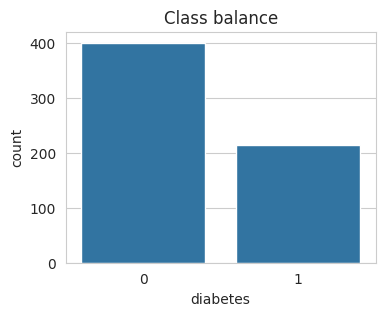

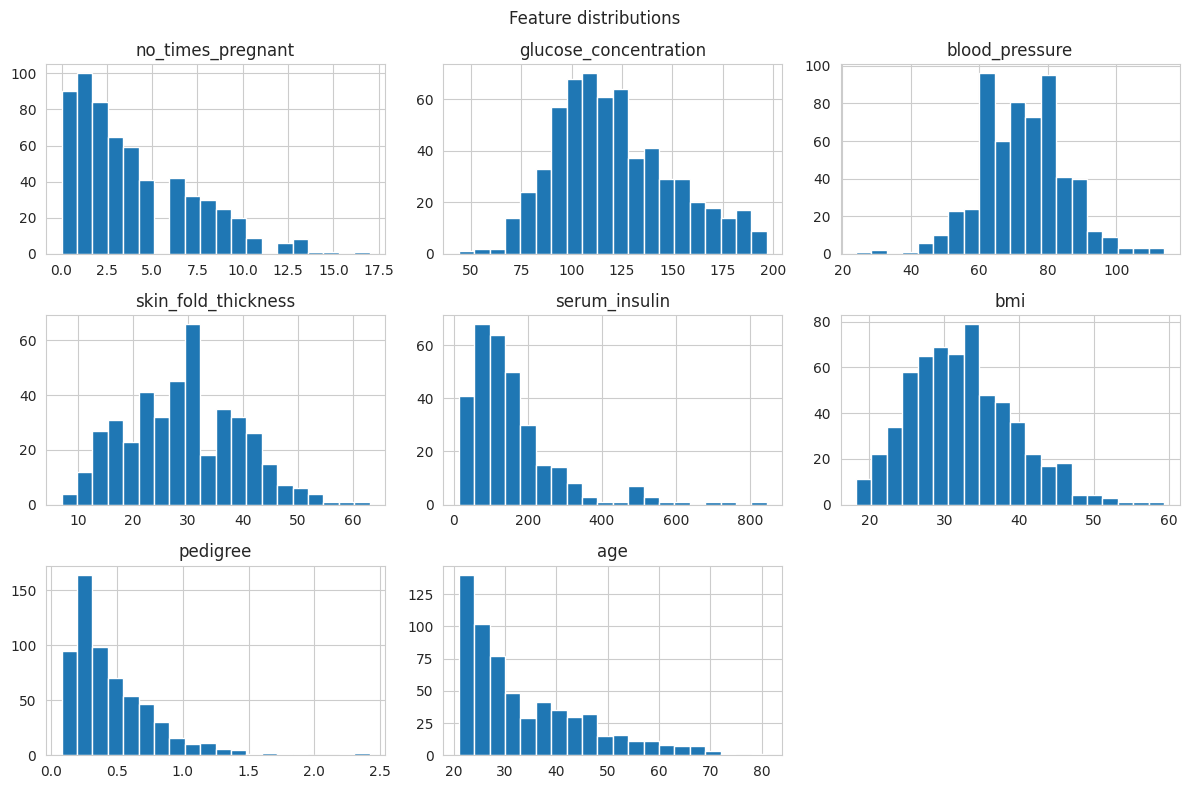

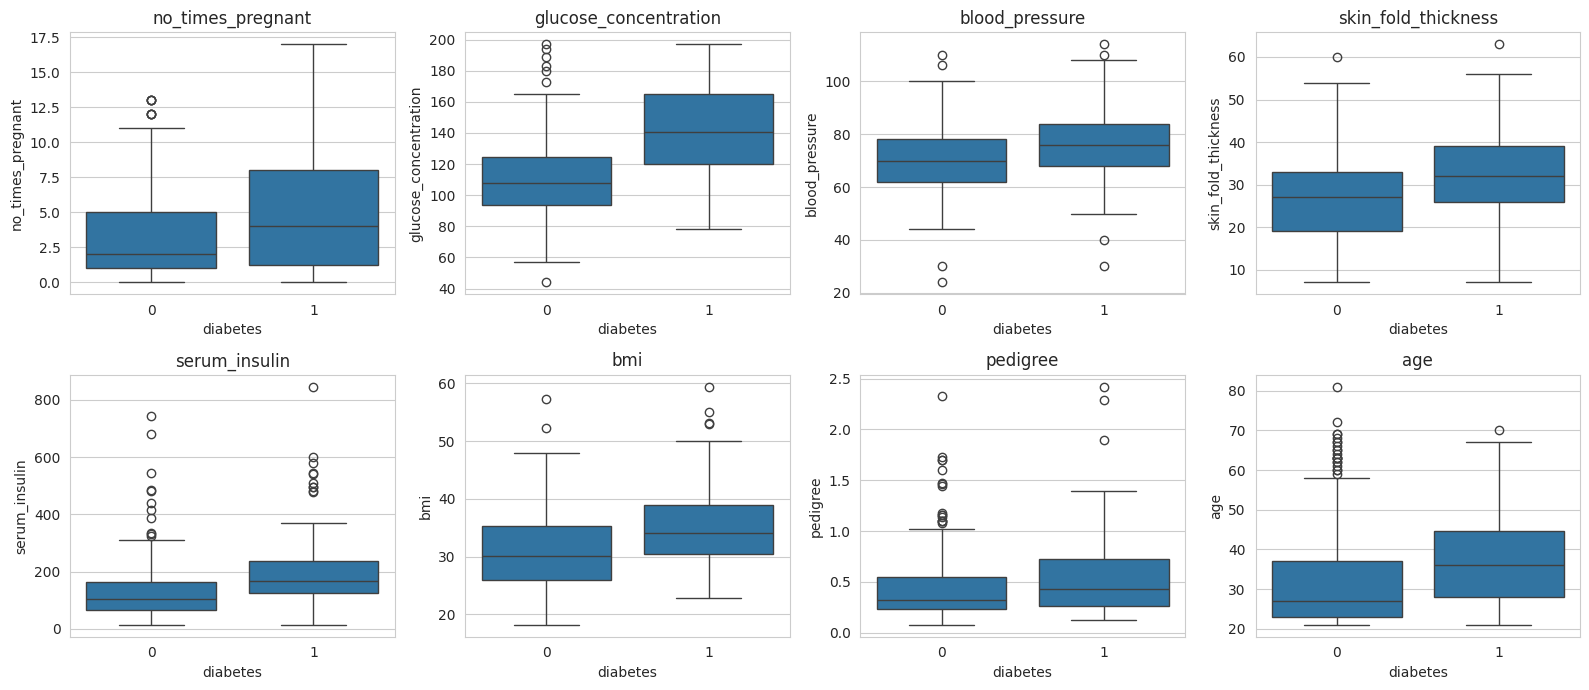

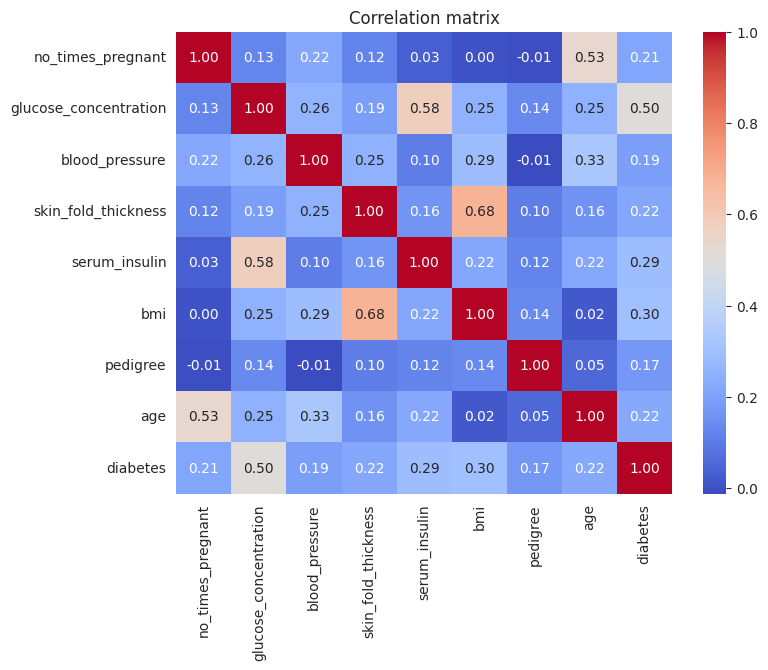

no_times_pregnant: 3 outliers
glucose_concentration: 0 outliers
blood_pressure: 9 outliers
skin_fold_thickness: 2 outliers
serum_insulin: 20 outliers
bmi: 6 outliers
pedigree: 26 outliers
age: 9 outliers


In [ ]:
# 3. Target and EDA

# 3.1 Class balance
counts = train['diabetes'].value_counts()
pct = (train['diabetes'].value_counts(normalize=True) * 100).round(1)
print(pd.DataFrame({'count': counts, 'percent': pct}))

plt.figure(figsize=(4, 3))
sns.countplot(x='diabetes', data=train)
plt.title('Class balance')
plt.show()

features = [c for c in train.columns if c != 'diabetes']

# 3.2 Histograms
train[features].hist(bins=20, figsize=(12, 8))
plt.suptitle('Feature distributions')
plt.tight_layout()
plt.show()

# 3.3 Boxplots by target
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(x='diabetes', y=col, data=train, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# 3.4 Correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(train.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation matrix')
plt.show()

# 3.5 Outlier count with the IQR rule
for col in features:
    q1, q3 = train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((train[col] < low) | (train[col] > high)).sum()
    print(f'{col}: {n} outliers')

## Markdown

We check class balance first, because it decides which metrics we trust. Then we look at how each feature differs by diabetes, and how features relate to each other.

1. Displays the class counts and percentages for the `diabetes` target variable.
2. Plots the distribution of each feature to examine its spread, skewness, and potential anomalies.
3. Compares feature distributions between diabetic and non-diabetic patients to identify potential differences and patterns.
4. Displays a correlation matrix showing the relationships between all numerical features and the target variable.
5. Counts IQR-based outliers for each feature. Outliers are identified for further analysis but are not removed.

**EDA Output:**

1\. Class balance: 400 non-diabetic (65.1%) and 214 diabetic (34.9%). The imbalance is moderate, about 2 to 1. Accuracy alone is misleading here, because a model that always predicts “no diabetes” scores 65.1%. That is our baseline accuracy to beat. We use stratified splits, and we compare `class_weight='balanced'` against no weighting. We skip SMOTE for now, since the imbalance is mild and the dataset is small.

2\. Skew: Insulin, pedigree, pregnancies, and age are right-skewed. A log transform on insulin and pedigree helps Logistic Regression. Tree models do not need it.

3\. Feature signal: Glucose is the strongest feature (0.50 with the target). BMI (0.30) and insulin (0.29) follow. This matches medical knowledge, so nothing looks suspicious.

4\. Correlated pairs: Skin fold and BMI (0.68), and pregnancies and age (0.53). These are moderate, not extreme. We keep all features, since Logistic Regression handles this level and trees are not affected. One caution: skin fold has 30.5% missing values, so its correlation with BMI is computed on fewer rows.

5\. Outliers: Counts are small, except pedigree (26) and insulin (20). These look like real extreme patients, not errors. We keep them. Log transforms and tree models handle them.


# 4. Feature Engineering and Split

In [ ]:
# 4. Feature engineering and split
from sklearn.model_selection import train_test_split

def add_features(df):
    df = df.copy()

    # Missing flags (created before imputation)
    df['insulin_missing'] = df['serum_insulin'].isna().astype(int)
    df['skinfold_missing'] = df['skin_fold_thickness'].isna().astype(int)

    # Log transforms for skewed columns (NaN stays NaN)
    df['log_insulin'] = np.log1p(df['serum_insulin'])
    df['log_pedigree'] = np.log1p(df['pedigree'])

    # Age group as a number: 0 = 21-30, 1 = 31-40, 2 = 41-50, 3 = 51+
    df['age_group'] = pd.cut(df['age'], bins=[0, 30, 40, 50, 120],
                             labels=[0, 1, 2, 3]).astype(int)

    # BMI group: 0 = under 18.5, 1 = normal, 2 = overweight, 3 = obese
    # NaN stays NaN and is imputed later
    df['bmi_group'] = pd.cut(df['bmi'], bins=[0, 18.5, 25, 30, 100],
                             labels=[0, 1, 2, 3], right=False).astype(float)

    # Glucose group: 0 = under 100, 1 = 100-125, 2 = 126+
    df['glucose_group'] = pd.cut(df['glucose_concentration'],
                                 bins=[0, 100, 126, 500],
                                 labels=[0, 1, 2], right=False).astype(float)
    return df

train_fe = add_features(train)
test_fe = add_features(test)

X = train_fe.drop(columns='diabetes')
y = train_fe['diabetes']

# Stratified 80/20 split
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print('Train:', X_train.shape, ' Val:', X_val.shape)
print('\nTrain class %:')
print((y_train.value_counts(normalize=True) * 100).round(1))
print('\nVal class %:')
print((y_val.value_counts(normalize=True) * 100).round(1))
print('\nNew feature list:', list(X.columns))

Train: (491, 15)  Val: (123, 15)

Train class %:
diabetes
0    65.2
1    34.8
Name: proportion, dtype: float64

Val class %:
diabetes
0    65.0
1    35.0
Name: proportion, dtype: float64

New feature list: ['no_times_pregnant', 'glucose_concentration', 'blood_pressure', 'skin_fold_thickness', 'serum_insulin', 'bmi', 'pedigree', 'age', 'insulin_missing', 'skinfold_missing', 'log_insulin', 'log_pedigree', 'age_group', 'bmi_group', 'glucose_group']


## Markdown

1. `insulin_missing` and `skinfold_missing` flags. Missingness may carry signal.
2. `bmi_group`: underweight, normal, overweight, obese (WHO cut-offs).
3. `glucose_group`: normal, prediabetic, diabetic range (cut-offs from the test description: under 140, 140 to 199, 200 and above). Max glucose in train is 197, so the top group will be empty. We will use under 100, 100 to 125, and 126 and above instead, which are common fasting-style thresholds. Note this test is 2-hour glucose, so the cut-offs are approximate. We let validation results decide if the feature helps.
4. `age_group`: 21 to 30, 31 to 40, 41 to 50, 51 and above.
5. `log_insulin` and `log_pedigree` for the linear model.


The missing flags must be created before imputation. Then we split.

**Output:**

1\. Training has 491 rows, and validation has 123 rows.

2\. Both sets maintain the 65/35 class ratio, confirming that the stratified split worked.

3\. There are 15 features, and `p_id` has been removed.



# 5. Baseline, Pipeline, and Model Comparison

In [ ]:
# 5-6. Baseline, pipeline, and model comparison
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

def make_pipe(model):
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('model', model)
    ])

models = {
    'Dummy (baseline)': DummyClassifier(strategy='most_frequent'),
    'LogReg': LogisticRegression(max_iter=1000, random_state=SEED),
    'LogReg balanced': LogisticRegression(max_iter=1000, class_weight='balanced',
                                          random_state=SEED),
    'RandomForest': RandomForestClassifier(n_estimators=300, random_state=SEED),
    'RandomForest balanced': RandomForestClassifier(n_estimators=300,
                                                    class_weight='balanced',
                                                    random_state=SEED),
    'GradientBoosting': GradientBoostingClassifier(random_state=SEED),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

rows = []
for name, model in models.items():
    res = cross_validate(make_pipe(model), X_train, y_train,
                         cv=cv, scoring=scoring, n_jobs=-1)
    row = {'model': name}
    for m in scoring:
        row[m] = res['test_' + m].mean()
    rows.append(row)

results = pd.DataFrame(rows).set_index('model').round(3)
results.sort_values('roc_auc', ascending=False)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
LogReg balanced,0.754,0.625,0.743,0.677,0.837
LogReg,0.752,0.685,0.538,0.600,0.836
GradientBoosting,0.754,0.664,0.597,0.627,0.832
RandomForest balanced,0.752,0.670,0.567,0.613,0.819
RandomForest,0.756,0.682,0.568,0.618,0.818
Dummy (baseline),0.652,0.000,0.000,0.000,0.500


## Markdown

We use 5-fold stratified cross-validation on the training set only. The validation set stays untouched until we tune and pick a threshold. With only 491 training rows, CV gives more stable scores than one small split.

Each model sits inside a pipeline with median imputation and scaling. Inside CV, the pipeline refits the imputer and scaler on each fold’s training part. This prevents leakage.

We test:

1. A dummy baseline (always predicts “no diabetes”).
2. Logistic Regression, with and without `class_weight='balanced'`.
3. Random Forest, with and without `class_weight='balanced'`.
4. Gradient Boosting (it has no class weight option).

This answers the question of whether class weights help, using the same folds for every model.

**Results:**

1\. Baseline: The dummy gets 65.2% accuracy, 0 recall, and 0.500 ROC-AUC, as expected. Every real model beats it by about 10 points of accuracy.

2\. Accuracy is flat: All real models sit between 0.752 and 0.756. Accuracy cannot separate them, so we look at recall and ROC-AUC.

3\. Class weights help Logistic Regression a lot. Recall rises from 0.538 to 0.743. Precision drops from 0.685 to 0.625, and F1 rises from 0.600 to 0.677. ROC-AUC barely moves (0.836 vs 0.837), which is expected. Weights shift the decision boundary, not the ranking.

4\. Class weights do nothing for Random Forest. Recall goes from 0.568 to 0.567. Trees fit the training folds almost perfectly, so the weights have little effect on predictions.

5\. Best ranking: Logistic Regression has the top ROC-AUC (0.837), ahead of Gradient Boosting (0.832) and Random Forest (0.818). The simple model matches or beats the complex ones. This often happens on small tabular data (491 rows) with a mostly linear signal like glucose.

6\. Caution: The gaps in ROC-AUC (0.837 vs 0.832) are small. With 491 rows, they are within noise. We should not claim one is truly better yet.

**Decision**

Since recall for diabetic patients matters most, and Logistic Regression balanced has the best recall and F1, we make it the lead model. We tune two models:

1. Logistic Regression (balanced): tune `C` and `penalty`.
2. Gradient Boosting: tune a small grid, since it has the best non-linear score.

We drop Random Forest. It is not better than the others, and the class weights did nothing.

We use ROC-AUC as the tuning score. It does not depend on the threshold. We pick the threshold afterward on the validation set, so recall does not get tuned twice.

# 7. Hyperparameter Tuning

In [ ]:
# 7. Hyperparameter tuning
from sklearn.model_selection import GridSearchCV

# Logistic Regression
lr_pipe = make_pipe(LogisticRegression(max_iter=2000, class_weight='balanced',
                                       solver='liblinear', random_state=SEED))
lr_grid = {
    'model__C': [0.01, 0.1, 0.3, 1, 3, 10],
    'model__penalty': ['l1', 'l2'],
}
lr_search = GridSearchCV(lr_pipe, lr_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
lr_search.fit(X_train, y_train)

# Gradient Boosting
gb_pipe = make_pipe(GradientBoostingClassifier(random_state=SEED))
gb_grid = {
    'model__n_estimators': [50, 100, 200],
    'model__learning_rate': [0.03, 0.1],
    'model__max_depth': [2, 3],
    'model__subsample': [0.7, 1.0],
}
gb_search = GridSearchCV(gb_pipe, gb_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
gb_search.fit(X_train, y_train)

print('LogReg best params:', lr_search.best_params_)
print('LogReg best CV ROC-AUC:', round(lr_search.best_score_, 3))
print()
print('GradBoost best params:', gb_search.best_params_)
print('GradBoost best CV ROC-AUC:', round(gb_search.best_score_, 3))

LogReg best params: {'model__C': 0.1, 'model__penalty': 'l2'}
LogReg best CV ROC-AUC: 0.84

GradBoost best params: {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 200, 'model__subsample': 0.7}
GradBoost best CV ROC-AUC: 0.84


## Markdown

1. Searches 12 parameter combinations for Logistic Regression and 24 for Gradient Boosting.
2. Uses the same 5-fold cross-validation strategy as before, with the training set only.
3. Prints the best hyperparameter settings and their cross-validation ROC-AUC scores.

**Output:**

1\. Both models reach 0.840 CV ROC-AUC. Logistic Regression gained 0.003 (0.837 to 0.840). Gradient Boosting gained 0.008 (0.832 to 0.840). Both gains are tiny and within noise.

2\. Tuned settings point to simplicity. Logistic Regression picked `C=0.1`, which is moderate regularization. Gradient Boosting picked the shallowest trees (`max_depth=2`), the slowest learning rate (0.03), and `subsample=0.7`. The search kept pushing Gradient Boosting toward simpler, smoother models. That fits our earlier finding that the signal is mostly linear.

3\. One caution: The best CV score comes from picking the winner out of 12 or 24 settings on the same folds. It is slightly optimistic. The validation set gives the honest check.


**Decision**

Since the scores tie, we let the validation set and the project goal decide. We compare three things on the 123 validation rows:

1. Tuned Logistic Regression (balanced).
2. Tuned Gradient Boosting.
3. The dummy baseline, for reference.

Gradient Boosting has no class weight option. Its default 0.5 threshold will likely give lower recall. So the threshold step matters most for it, and we will tune thresholds for both models on fair terms.

To avoid tuning the threshold on the same rows we report on, we use out-of-fold predictions from the training set to pick the threshold. Then we report validation results once at that threshold.

# 7. Threshold Selection and Validation Evaluation

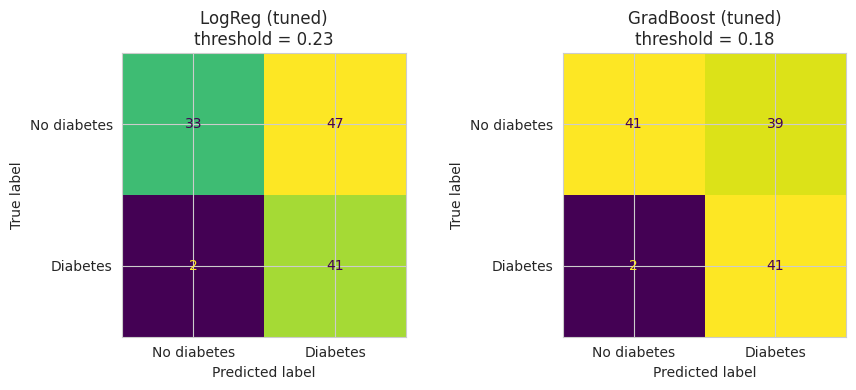

Dummy val accuracy: 0.65


accuracy  precision  recall     f1  roc_auc
model             threshold                                                 
LogReg (tuned)    0.5               0.699      0.550   0.767  0.641    0.838
                  0.23 (chosen)     0.602      0.466   0.953  0.626    0.838
GradBoost (tuned) 0.5               0.789      0.707   0.674  0.690    0.853
                  0.18 (chosen)     0.667      0.512   0.953  0.667    0.853

In [ ]:
# 8. Threshold selection and validation evaluation
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (precision_recall_curve, fbeta_score, accuracy_score,
                             precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)

best_models = {
    'LogReg (tuned)': lr_search.best_estimator_,
    'GradBoost (tuned)': gb_search.best_estimator_,
}

def pick_threshold(y_true, proba, beta=2):
    thresholds = np.arange(0.1, 0.91, 0.01)
    scores = [fbeta_score(y_true, proba >= t, beta=beta) for t in thresholds]
    return thresholds[int(np.argmax(scores))]

rows = []
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for ax, (name, model) in zip(axes, best_models.items()):
    # 1. Out-of-fold probabilities on training data only
    oof = cross_val_predict(model, X_train, y_train, cv=cv,
                            method='predict_proba')[:, 1]
    thr = pick_threshold(y_train, oof)

    # 2. Fit on training data, predict validation
    model.fit(X_train, y_train)
    val_proba = model.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, val_proba)

    for label, t in [('0.5', 0.5), (f'{thr:.2f} (chosen)', thr)]:
        pred = (val_proba >= t).astype(int)
        rows.append({
            'model': name, 'threshold': label,
            'accuracy': accuracy_score(y_val, pred),
            'precision': precision_score(y_val, pred),
            'recall': recall_score(y_val, pred),
            'f1': f1_score(y_val, pred),
            'roc_auc': auc,
        })

    # Confusion matrix at the chosen threshold
    pred = (val_proba >= thr).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_val, pred),
                           display_labels=['No diabetes', 'Diabetes']).plot(ax=ax,
                           colorbar=False)
    ax.set_title(f'{name}\nthreshold = {thr:.2f}')

plt.tight_layout()
plt.show()

# Dummy reference on validation
dummy = make_pipe(DummyClassifier(strategy='most_frequent')).fit(X_train, y_train)
print('Dummy val accuracy:', round(accuracy_score(y_val, dummy.predict(X_val)), 3))

pd.DataFrame(rows).set_index(['model', 'threshold']).round(3)

## Markdown

1. Generates out-of-fold predicted probabilities on the training set for each tuned model.
2. Selects the threshold that maximizes the F2 score. F2 gives recall twice as much weight as precision, which aligns with the goal of minimizing missed diabetic cases.
3. Fits each model on the full training set. Evaluates the validation set using both the default threshold of 0.5 and the selected threshold.
4. Displays the confusion matrix and ROC-AUC for each model.


1\. Selects each model’s threshold using only the training data, keeping the validation set separate.

2\. Reports validation metrics at the default threshold of 0.5 and at the selected threshold to show how threshold changes affect model performance.

3\. Plots one confusion matrix for each model.


**Validation Results:**

1\. The chosen thresholds are too low. At 0.23, Logistic Regression flags 88 of 123 patients as diabetic (33 true negatives + 47 false positives = 80 healthy patients, and 47 of them are flagged wrongly). Gradient Boosting flags 80. Both catch 41 of 43 diabetic patients (recall 0.953). But Logistic Regression accuracy is 0.602, which is below the dummy baseline (0.65). Gradient Boosting is barely above it (0.667).

2\. Cause: F2 pushes too hard toward recall. F2 treats a missed patient as 4 times worse than a false alarm. With a 35% positive rate, that rewards flagging almost everyone. Flagging everyone gives F2 of about 0.73, and our Logistic Regression result is only 0.79.

3\. Second cause: double correction for Logistic Regression. `class_weight='balanced'` already shifts its probabilities upward. Lowering the threshold to 0.23 on top of that corrects for imbalance twice.

4\. Gradient Boosting is better at both thresholds. At 0.5: accuracy 0.789 vs 0.699, F1 0.690 vs 0.641, ROC-AUC 0.853 vs 0.838. At the chosen threshold: same recall, but 41 true negatives vs 33. The gap is real in this sample, but 123 rows is small. One patient changes recall by 2.3 points. The CV scores tied (0.840), so I treat Gradient Boosting as a slight favorite, not a proven winner.

5\. The AUC values did not change with the threshold (0.838 and 0.853). The ranking is fine. Only the cut-off is the problem.


# 8. Threshold Analysis with a Recall Target

In [ ]:
# 8b. Threshold analysis with a recall target
oof_probs = {}
for name, model in best_models.items():
    oof_probs[name] = cross_val_predict(model, X_train, y_train, cv=cv,
                                        method='predict_proba')[:, 1]

def pick_threshold_recall(y_true, proba, min_recall=0.85):
    # Highest threshold that still meets the recall target
    thresholds = np.arange(0.05, 0.96, 0.01)
    ok = [t for t in thresholds if recall_score(y_true, proba >= t) >= min_recall]
    return max(ok)

def metrics_at(y_true, proba, t):
    pred = (proba >= t).astype(int)
    return {
        'threshold': round(t, 2),
        'recall': recall_score(y_true, pred),
        'precision': precision_score(y_true, pred),
        'specificity': recall_score(y_true, pred, pos_label=0),
        'accuracy': accuracy_score(y_true, pred),
        'pct_flagged': pred.mean(),
    }

# Part 1: OOF trade-off table (training data only)
for name in best_models:
    print(f'\n{name}: out-of-fold trade-off')
    tbl = pd.DataFrame([metrics_at(y_train, oof_probs[name], t)
                        for t in [0.2, 0.3, 0.4, 0.5, 0.6]])
    print(tbl.round(3).to_string(index=False))

# Part 2: pick threshold with recall target 0.85, then score validation once
rows = []
for name, model in best_models.items():
    thr = pick_threshold_recall(y_train, oof_probs[name], min_recall=0.85)
    val_proba = model.predict_proba(X_val)[:, 1]
    row = {'model': name}
    row.update(metrics_at(y_val, val_proba, thr))
    pred = (val_proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
    row.update({'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp})
    rows.append(row)

pd.DataFrame(rows).set_index('model').round(3)


LogReg (tuned): out-of-fold trade-off
 threshold  recall  precision  specificity  accuracy  pct_flagged
       0.2   0.994      0.462        0.381     0.595        0.749
       0.3   0.936      0.514        0.528     0.670        0.633
       0.4   0.848      0.580        0.672     0.733        0.509
       0.5   0.754      0.620        0.753     0.754        0.424
       0.6   0.620      0.631        0.806     0.741        0.342

GradBoost (tuned): out-of-fold trade-off
 threshold  recall  precision  specificity  accuracy  pct_flagged
       0.2   0.895      0.546        0.603     0.705        0.570
       0.3   0.795      0.607        0.725     0.749        0.456
       0.4   0.702      0.649        0.797     0.764        0.377
       0.5   0.561      0.681        0.859     0.756        0.287
       0.6   0.474      0.711        0.897     0.749        0.232


,threshold,recall,precision,specificity,accuracy,pct_flagged,TN,FP,FN,TP
model,,,,,,,,,,
LogReg (tuned),0.39,0.814,0.507,0.575,0.659,0.561,46,34,8,35
GradBoost (tuned),0.24,0.884,0.521,0.562,0.675,0.593,45,35,5,38


## Markdown

**Fix: use a recall target instead of F2**

We state the goal directly: catch at least 85% of diabetic patients, and keep false alarms as low as possible. A screening test with a follow-up confirmation test can accept some false positives. It cannot accept many missed patients. The 85% target is a project choice, and you can change it.

We still pick the threshold on out-of-fold training predictions only. The validation set stays untouched for the final check. One honest note: we changed the rule after seeing validation results, because the F2 result was not practical. We did not tune on validation rows, but we should say this in the report.

1. Generates out-of-fold predicted probabilities for both models using the training data.
2. Reports recall, precision, specificity, accuracy, and the percentage of patients flagged as diabetic at five different thresholds to illustrate the trade-offs.
3. Selects the highest threshold that maintains an out-of-fold recall of at least 0.85.
4. Evaluates each model once on the validation set using its selected threshold and prints the confusion matrix counts.

**Output:**

1\. The recall target worked. The thresholds are now sensible (0.39 and 0.24). The flagged share dropped from 65% to about 56% to 59% of patients.

2\. Validation recall landed near the target. Logistic Regression catches 35 of 43 diabetic patients (recall 0.814) and misses 8. Gradient Boosting catches 38 of 43 (recall 0.884) and misses 5. The target was 0.85, and both sit within about 4 points of it. That gap is normal with only 43 positives.

3\. The cost is many false alarms. Precision is 0.507 for Logistic Regression and 0.521 for Gradient Boosting. About half of the flagged patients are healthy (34 and 35 false positives). Accuracy is 0.659 and 0.675, barely above the dummy (0.65). Accuracy is not our goal here, but this is the real price of catching 85% of cases.

4\. This is a limit of the data, not a bug. The ROC-AUC is about 0.84. At that level, catching 85% of diabetic patients costs about a 40% false positive rate. No threshold changes this. Only better features or a better ranking would.

5\. The trade-off table lets you choose. Logistic Regression at threshold 0.5 gives recall 0.754 and specificity 0.753. At 0.4 it gives recall 0.848 and specificity 0.672. Each step up in recall costs more false alarms. A recall target of 0.85 only makes sense if a follow-up test is cheap.

6\. The models are still close. Gradient Boosting leads by 3 patients in recall and 0.015 in AUC on validation. The CV scores tied at 0.840. One validation split cannot separate them, and we have now looked at it several times.

Decision

We stop using the validation set to compare models. Instead, we merge training and validation (614 rows, 214 diabetic) and compare both tuned models with repeated 5-fold CV. We use two metrics that do not depend on a threshold:

1. ROC-AUC.
2. Specificity at 85% recall. This is the share of healthy patients correctly cleared when we catch 85% of diabetic patients. Higher is better.

Both models are scored on the same folds. Using 614 rows with 5 different fold splits gives a more stable answer than 123 rows.

One caution: the hyperparameters were tuned on the training part. This gives both models the same small optimism, so the comparison stays fair. The standard deviation we report shows variation across splits only. It does not show full uncertainty.

# 9. Final Model Comparison

In [ ]:
# 9. Final comparison with repeated CV on all labeled data
from sklearn.base import clone
from sklearn.metrics import roc_curve

X_all = pd.concat([X_train, X_val])
y_all = pd.concat([y_train, y_val])

def spec_at_recall(y_true, proba, target=0.85):
    fpr, tpr, _ = roc_curve(y_true, proba)
    i = np.argmax(tpr >= target)   # first point that reaches the recall target
    return 1 - fpr[i]

rows = []
for name, model in best_models.items():
    aucs, specs = [], []
    for seed in [1, 2, 3, 4, 5]:
        cv_r = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
        p = cross_val_predict(clone(model), X_all, y_all, cv=cv_r,
                              method='predict_proba')[:, 1]
        aucs.append(roc_auc_score(y_all, p))
        specs.append(spec_at_recall(y_all, p))
    rows.append({
        'model': name,
        'auc_mean': np.mean(aucs), 'auc_std': np.std(aucs),
        'spec_at_85_recall': np.mean(specs), 'spec_std': np.std(specs),
    })

pd.DataFrame(rows).set_index('model').round(3)

,auc_mean,auc_std,spec_at_85_recall,spec_std
model,,,,
LogReg (tuned),0.836,0.003,0.640,0.017
GradBoost (tuned),0.839,0.004,0.686,0.023


## Markdown

1. Merges the training and validation data into one labeled dataset.
2. Runs 5-fold cross-validation five times using different fold splits.
3. Records ROC-AUC and specificity at 85% recall for each run.
4. Reports the mean and standard deviation across the five runs.

**Result:**

1\. AUC is a tie. The gap is 0.003, and the standard deviations are 0.003 and 0.004. The two models rank patients equally well.

2\. Specificity at 85% recall favors Gradient Boosting. The gap is 0.046, about 2 times the standard deviation. In practice, Gradient Boosting clears about 18 more of the 400 healthy patients at the same recall.

3\. Caution: the five repeats reuse the same 614 rows. The standard deviation shows split noise only. The true uncertainty is larger.

4\. Other evidence points the same way. Gradient Boosting also led on the validation set (AUC 0.853 vs 0.838) and in the out-of-fold table. Each gap is small, but all point in one direction.

**Decision:**

My rule was to pick Logistic Regression if the gap was inside the noise. The AUC gap is inside the noise. The specificity gap is not. The project asks for the best-performing model, so I pick Gradient Boosting. The cost is lower interpretability, but permutation importance still explains it. In the report, say that the two models were close and that Gradient Boosting won by a small margin.

# 10. Final Model

Threshold per run: [0.3  0.29 0.3  0.29 0.3 ]
Final threshold: 0.3

Expected performance (out-of-fold):
threshold      0.300
recall         0.803
precision      0.622
specificity    0.738
accuracy       0.761
pct_flagged    0.450
dtype: float64

Confusion matrix, run 1 (rows = true, cols = predicted):
[[297 103]
 [ 41 173]]


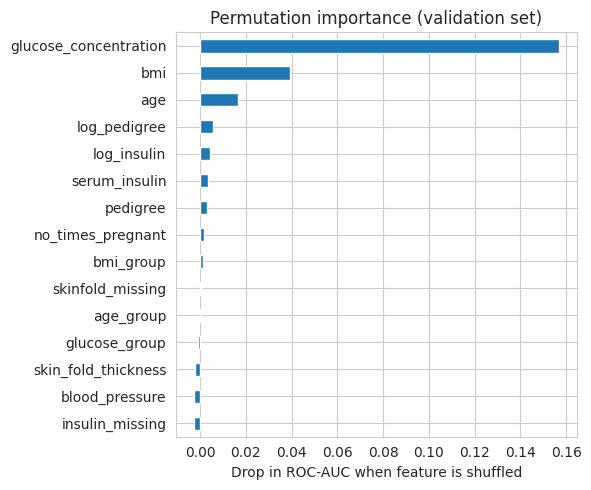

glucose_concentration    0.1567
bmi                      0.0392
age                      0.0166
log_pedigree             0.0059
log_insulin              0.0045
serum_insulin            0.0036
pedigree                 0.0030
no_times_pregnant        0.0018
bmi_group                0.0011
skinfold_missing         0.0002
age_group                0.0000
glucose_group           -0.0007
skin_fold_thickness     -0.0024
blood_pressure          -0.0024
insulin_missing         -0.0024
dtype: float64

Test rows: 154
Share flagged as diabetic: 0.494


In [ ]:
# 10. Final model, threshold, interpretation, test predictions
from sklearn.inspection import permutation_importance

final_model = clone(gb_search.best_estimator_)

# 10.1 Threshold for 80% recall (out-of-fold, all labeled data)
thrs, oofs = [], []
for seed in [1, 2, 3, 4, 5]:
    cv_r = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    p = cross_val_predict(clone(final_model), X_all, y_all, cv=cv_r,
                          method='predict_proba')[:, 1]
    oofs.append(p)
    thrs.append(pick_threshold_recall(y_all, p, min_recall=0.80))

thr = float(np.median(thrs))
print('Threshold per run:', np.round(thrs, 2))
print('Final threshold:', round(thr, 2))

# 10.2 Expected performance at this threshold (average of 5 runs)
perf = pd.DataFrame([metrics_at(y_all, p, thr) for p in oofs]).mean()
print('\nExpected performance (out-of-fold):')
print(perf.round(3))

pred0 = (oofs[0] >= thr).astype(int)
print('\nConfusion matrix, run 1 (rows = true, cols = predicted):')
print(confusion_matrix(y_all, pred0))

# 10.3 Permutation importance (fit on train, score on validation)
imp_model = clone(final_model).fit(X_train, y_train)
imp = permutation_importance(imp_model, X_val, y_val, scoring='roc_auc',
                             n_repeats=30, random_state=SEED)
imp_s = pd.Series(imp.importances_mean, index=X_val.columns).sort_values()

imp_s.plot.barh(figsize=(6, 5))
plt.xlabel('Drop in ROC-AUC when feature is shuffled')
plt.title('Permutation importance (validation set)')
plt.tight_layout()
plt.show()
print(imp_s.sort_values(ascending=False).round(4))

# 10.4 Refit on all labeled data and predict test.csv
final_model.fit(X_all, y_all)
test_proba = final_model.predict_proba(test_fe[X_all.columns])[:, 1]

out = pd.DataFrame({
    'p_id': test_ids.values,
    'probability': test_proba.round(4),
    'diabetes_pred': (test_proba >= thr).astype(int),
})
out.to_csv(path + 'predictions.csv', index=False)

print('\nTest rows:', len(out))
print('Share flagged as diabetic:', round(out['diabetes_pred'].mean(), 3))

## Markdown

1. Selects the threshold for 0.80 recall using out-of-fold predictions across all 614 rows. Repeats this process over five fold splits and takes the median threshold to improve stability.
2. Reports the expected model performance at the selected threshold.
3. Runs permutation importance using held-out validation data. Fits the model on the training set and evaluates feature importance on the validation set.
4. Refits the model on all 614 rows and generates predictions for `test.csv`.

**Output:**

1\. The threshold is stable. The five runs gave values from 0.29 to 0.30, so the final threshold is 0.30. This matches the expected value of 0.3.

2\. Expected performance at 0.30 (out-of-fold, all 614 rows):

- Recall: 0.803. We catch about 4 in 5 diabetic patients.
- Precision: 0.622. About 6 in 10 flagged patients are diabetic.
- Specificity: 0.738. About 74% of healthy patients are cleared.
- Accuracy: 0.761, which beats the dummy (0.652).
- Flagged share: 45%.

3\. Confusion matrix (run 1): 173 true positives, 41 missed diabetic patients, 103 false alarms, and 297 true negatives. Compared with the 0.85 target, the 0.80 target noticeably reduces false alarms. Specificity rises from about 0.69 to 0.74.

4\. Importance ranking is plausible. Glucose dominates (0.157 drop in AUC), followed by BMI (0.039) and age (0.017). This matches the EDA correlations and medical knowledge. Nothing points to leakage.

5\. Most other features add little. Pedigree, insulin, and pregnancies sit near zero. Several features are slightly negative (`skin_fold_thickness`, `blood_pressure`, `insulin_missing`, `glucose_group`). A negative value means shuffling the feature did not hurt the model's performance, so it adds little useful signal and may add noise. These values come from only 123 rows, so treat small differences as noise.

6\. Caution on interpretation. Importance shows what the model uses. It does not show what causes diabetes. Also, correlated features share credit. The `glucose_group` score is near zero because `glucose_concentration` already carries the same signal.

7\. Test predictions look consistent. 49.4% of test patients are flagged. That is higher than the 45% in out-of-fold results, but the test has only 154 rows, so a 4-point gap is within normal variation. It could also mean the test group has slightly higher glucose. A quick check of the test feature means against the training data would help confirm this.

# 11. Summary

## Conclusion

## Problem
Predict whether a patient has diabetes (`diabetes` = 1) from 8 medical measurements. This is binary classification. The class of interest is diabetic. A missed diabetic patient (false negative) is the worse error, so recall for class 1 is the main goal.

## Data
- Train: 614 rows. Test: 154 rows, with no labels.
- Class balance: 400 non-diabetic (65.1%), 214 diabetic (34.9%).
- Zeros in glucose, blood pressure, skin fold, insulin, and BMI are impossible values. They were treated as missing. Insulin is missing in 49.5% of rows and skin fold in 30.5%.
- No duplicates. Outliers were kept, since they look like real patients.

## Method
1. Cleaned the data and engineered features: missing flags, log transforms, and age, BMI, and glucose groups.
2. Split the training data 80/20 with stratification. Used a pipeline (median imputation, scaling) so preprocessing was fit on training data only.
3. Compared a dummy baseline, Logistic Regression, Random Forest, and Gradient Boosting using 5-fold CV.
4. Tuned Logistic Regression and Gradient Boosting with GridSearchCV on ROC-AUC.
5. Compared the two tuned models with 5 x 5-fold CV on all 614 labeled rows.
6. Chose the decision threshold from out-of-fold predictions to reach 80% recall.

## Results
- Baseline accuracy: 0.652 (always predicts non-diabetic).
- Tuned CV ROC-AUC: 0.840 for both models.
- Repeated CV on all data: ROC-AUC 0.836 (Logistic Regression) and 0.839 (Gradient Boosting). Specificity at 85% recall: 0.640 and 0.686.
- Gradient Boosting was chosen by a small margin. The two models were close.
- Final threshold: 0.30. Expected performance (out-of-fold): recall 0.803, precision 0.622, specificity 0.738, accuracy 0.761.
- Out-of-fold confusion matrix (run 1): 297 true negatives, 103 false positives, 41 false negatives, 173 true positives.
- Top features by permutation importance: glucose (0.157), BMI (0.039), age (0.017).
- Test predictions: 49.4% of 154 patients flagged as diabetic. Saved to `predictions.csv`.

## Limitations
1. Small dataset (614 labeled rows). Differences between models are small and may not hold on new data.
2. Many missing values were imputed with the median. Insulin and skin fold are half or a third imputed.
3. The 80% recall target is a project choice. About 1 in 5 diabetic patients is missed, and about 6 in 10 healthy patients (The 80% recall target is a project choice. About 1 in 5 diabetic patients is missed, and about 1 in 4 healthy patients is flagged by mistake (specificity 0.738). A real clinic would set the target based on the cost of a follow-up test).
4. We changed the threshold rule from F2 to a recall target after seeing that F2 flagged almost everyone. The validation set was not used to tune the new rule, but this change should be stated.
5. The test set has no labels, so test performance is unknown. The expected performance comes from cross-validation only.
6. Feature importance shows what the model uses, not what causes diabetes. Probabilities were not checked for calibration.

## Recommendations
1. Try dropping weak features and compare with repeated CV.
2. Try better imputation, such as KNN or iterative imputation.
3. Check probability calibration if the probabilities will be used as risk scores.
4. Collect more data or add features (for example, family history or HbA1c).